<a href="https://colab.research.google.com/github/archanat2402/used-car-prices-eda/blob/main/Python_%26_Pandas_EDA_TASK_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚗 Exploratory Data Analysis: Used Car Prices

**Author:** ARCHANA T
**Role:** Data Science Intern  
**Date:** November 2026  
**Dataset:** [CarDekho Used Car Data (Car Details v3)](https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho)

---

## 1. Introduction

### 1.1 Objective
This report presents an exploratory data analysis (EDA) of used car listings in India. The analysis reviews the content and quality of the data, identifies patterns and unusual values, and examines which factors are linked to a car's selling price.

### 1.2 About the Dataset
The data comes from CarDekho and is available on Kaggle (file: **Car Details v3**). It contains **8,128 used car listings** and **13 columns**. Each row represents one car. The columns describe its name, year, selling price (INR), kilometres driven, fuel type, seller type, transmission, number of previous owners, mileage, engine size, power, torque and number of seats.

The data required cleaning. About 3% of listings had no technical specifications, and 1,202 rows (14.8%) were exact duplicates. After duplicates were removed, **6,926 unique listings** remained. Text columns containing units (for example, "23.4 kmpl") were converted to numbers, and two new features were created: vehicle **age** and **brand**.

### 1.3 Key Questions
1. How is the selling price distributed, and are there unusual values?
2. How do vehicle age and kilometres driven relate to selling price?
3. Do fuel type and transmission show a difference in price?
4. Do dealers and individual sellers price cars differently?

### 1.4 Report Structure
| Section | Content |
|---|---|
| 1 | Introduction |
| 2 | Environment Setup |
| 3 | Data Overview |
| 4 | Data Quality Assessment (missing values and duplicates) |
| 5 | Data Cleaning and Feature Engineering |
| 6 | Univariate and Bivariate Analysis (charts) |
| 7 | Key Findings |
| 8 | Limitations and Conclusion |

### 1.5 Methodology
- Every data change is documented together with the reason for it.
- Each chart is followed by a short written interpretation.

## 2. Environment Setup

This section loads the Python libraries used in the analysis: pandas for data handling, and matplotlib and seaborn for charts. It also sets display options so that tables and charts are clean and easy to read.

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Configuration
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Version check
print("pandas    :", pd.__version__)
print("numpy     :", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn   :", sns.__version__)

pandas    : 2.2.3
numpy     : 2.4.6
matplotlib: 3.10.0
seaborn   : 0.13.2


**Configuration Notes**
- `RANDOM_STATE = 42` is set so that results can be reproduced by anyone who runs the notebook.
- Numbers are displayed with two decimal places to keep tables tidy.
- All charts use the seaborn `whitegrid` style for a consistent appearance.

## 3. Data Overview

This section describes the basic structure of the dataset before any analysis begins. It covers the size of the data, the type of each column, memory usage, and a sample of the actual records.

### 3.1 Loading the Data
**Objective:** Confirm that the dataset loads correctly and check its size.

The Kaggle source contains four files. The file `Car details v3.csv` was selected because it meets the project requirements (more than 1,000 rows and at least 8 columns) and contains realistic data quality issues, such as missing values and duplicate records. The original data is stored in `df_raw`, and all further work is done on a copy (`df`).

In [7]:
# Load the raw data
import os
import pandas as pd
import kagglehub

try:
    # Download the latest version of the dataset from Kaggle dynamically
    print("Downloading dataset using kagglehub...")
    dataset_path = kagglehub.dataset_download("nehalbirla/vehicle-dataset-from-cardekho")
    DATA_PATH = os.path.join(dataset_path, "Car details v3.csv")
except Exception as e:
    print(f"Kagglehub download failed ({e}), falling back to local files...")
    DATA_PATH = "data/Car details v3.csv"

# Fallback check
if not os.path.exists(DATA_PATH):
    # Try looking in the root directory as well
    if os.path.exists("Car details v3.csv"):
        DATA_PATH = "Car details v3.csv"
    else:
        raise FileNotFoundError(
            f"Could not find dataset at '{DATA_PATH}'. "
            "Please upload the 'Car details v3.csv' file using the file explorer on the left."
        )

print(f"Loading dataset from: {DATA_PATH}")
df_raw = pd.read_csv(DATA_PATH)

# Work on a copy; the raw data stays untouched
df = df_raw.copy()

print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Using Colab cache for faster access to the 'vehicle-dataset-from-cardekho' dataset.
Loading dataset from: /kaggle/input/vehicle-dataset-from-cardekho/Car details v3.csv
Rows    : 8,128
Columns : 13


### 3.2 First and Last Records
**Objective:** Review sample records and check whether the data follows any sort order.

The first and last five rows show what a typical record looks like. The data is not sorted by year, price or name. The last two rows are identical, which suggests duplicate records. This is checked formally in Section 4.

In [8]:
print("=== First 5 rows ===")
display(df.head())

print("\n=== Last 5 rows ===")
display(df.tail())

=== First 5 rows ===


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.00
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.00
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.00
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.00
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.00



=== Last 5 rows ===


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.5 kmpl,1197 CC,82.85 bhp,113.7Nm@ 4000rpm,5.00
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.8 kmpl,1493 CC,110 bhp,"24@ 1,900-2,750(kgm@ rpm)",5.00
8125,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.3 kmpl,1248 CC,73.9 bhp,190Nm@ 2000rpm,5.00
8126,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.00
8127,Tata Indigo CR4,2013,290000,25000,Diesel,Individual,Manual,First Owner,23.57 kmpl,1396 CC,70 bhp,140Nm@ 1800-3000rpm,5.00


### 3.3 Column Data Types
**Objective:** Check whether each column is stored in an appropriate data type and identify columns with missing values.

The dataset has 13 columns. The columns `mileage`, `engine`, `max_power` and `torque` are stored as text because their values include units (for example, "23.4 kmpl" or "1248 CC"). These columns are converted to numbers in Section 5. The columns `mileage`, `engine`, `max_power`, `torque` and `seats` also contain missing values (about 215 to 222 each).

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB


### 3.4 Memory Usage
**Objective:** Measure the memory used by each column and check whether it can be reduced.

The dataset uses about 4.4 MB of memory, which is small enough for analysis in pandas. Text columns use far more memory (about 436 to 589 KB each) than numeric columns (63.5 KB each). Columns with few distinct values, such as `fuel`, `seller_type` and `transmission`, could be converted to the `category` type to reduce memory use. This is not needed for a dataset of this size.

In [10]:
mem = df.memory_usage(deep=True)
mem_df = pd.DataFrame({
    "Column": mem.index,
    "Memory (KB)": (mem.values / 1024).round(2)
})
display(mem_df)
print(f"\nTotal memory: {mem.sum() / 1024:,.2f} KB  ({mem.sum() / 1024**2:.2f} MB)")

,Column,Memory (KB)
0,Index,0.13
1,name,588.78
2,year,63.50
3,selling_price,63.50
4,km_driven,63.50
5,fuel,436.28
6,seller_type,465.30
7,transmission,439.64
8,owner,479.85
9,mileage,458.07



Total memory: 4,516.42 KB  (4.41 MB)


### 3.5 Column Classification
**Objective:** Identify numeric and categorical columns and count the distinct values in each.

Four columns are numeric (`year`, `selling_price`, `km_driven`, `seats`) and nine are stored as text. This classification is provisional, because four of the text columns (`mileage`, `engine`, `max_power`, `torque`) actually contain numeric values. The column `name` has 2,058 distinct values, so it works as an identifier and not as a category. The columns `fuel` (4 values), `seller_type` (3), `transmission` (2) and `owner` (5) are true categorical variables. The column `seats` is numeric by type but has only 9 distinct values, so it behaves like a category.

In [11]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numeric columns    :", numeric_cols)
print("Categorical columns:", categorical_cols)

print("\nUnique values per column:")
display(df.nunique().to_frame("Unique Values"))

Numeric columns    : ['year', 'selling_price', 'km_driven', 'seats']
Categorical columns: ['name', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque']

Unique values per column:


,Unique Values
name,2058
year,29
selling_price,677
km_driven,921
fuel,4
seller_type,3
transmission,2
owner,5
mileage,393
engine,121


### 3.6 Structural Summary
**Objective:** Summarise the main findings from the data overview.

- **Size:** The dataset has 8,128 rows and 13 columns. It uses about 4.4 MB of memory, which is small enough for analysis in pandas.
- **Completeness:** The first eight columns have no missing values. The last five (`mileage`, `engine`, `max_power`, `torque`, `seats`) have 215 to 222 missing values each (about 2.7%). These are analysed in Section 4.
- **Data types:** Four columns (`mileage`, `engine`, `max_power`, `torque`) are stored as text because their values include units or mixed formats. They are converted to numbers in Section 5.
- **Identifier column:** `name` has 2,058 distinct values, so it is not useful as a category. A `brand` feature is extracted from it instead.
- **Categorical columns:** `fuel` (4 values), `seller_type` (3), `transmission` (2) and `owner` (5) are true categorical variables. Converting them to the `category` type would reduce memory use, but this is not needed at this dataset size.
- **Seats:** `seats` is stored as a decimal number but has only 9 distinct values, so it behaves like a category.
- **Duplicates:** The last two rows are identical, which suggests duplicate records. These are examined in Section 4.
- **Planned features:** `age` is derived from `year`, and `brand` is derived from `name`.

## 4. Data Quality Assessment

This section checks the dataset for missing values and duplicate records and decides how to handle them. Every decision is documented together with the reason for it.

### 4.1 Missing Values
**Objective:** Identify which columns have missing data and measure how much is missing.

Five columns contain missing values: `torque` (222), `mileage` (221), `engine` (221), `seats` (221) and `max_power` (215). Each is missing in about 2.7% of rows. The other eight columns are complete. In total, 222 rows (2.73%) have at least one missing value.

In [12]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing %": missing_pct
}).sort_values("Missing Count", ascending=False)

display(missing_df)

print(f"\nColumns with missing values : {(missing_count > 0).sum()} of {df.shape[1]}")
print(f"Total missing cells         : {missing_count.sum():,}")
print(f"Rows with at least one gap  : {df.isnull().any(axis=1).sum():,} of {len(df):,}")

,Missing Count,Missing %
torque,222,2.73
seats,221,2.72
engine,221,2.72
mileage,221,2.72
max_power,215,2.65
fuel,0,0.00
km_driven,0,0.00
selling_price,0,0.00
year,0,0.00
name,0,0.00



Columns with missing values : 5 of 13
Total missing cells         : 1,100
Rows with at least one gap  : 222 of 8,128


### 4.2 Missing Value Visualisation
**Objective:** Check whether the missing values are scattered randomly or occur together in the same rows.

The bar chart shows that the five affected columns each have about 2.65% to 2.73% missing values. The heatmap shows thin horizontal lines in the last five columns, and these lines line up across the columns. This means the same listings are missing several specification fields at once. The pattern is confirmed with counts in Section 4.3.

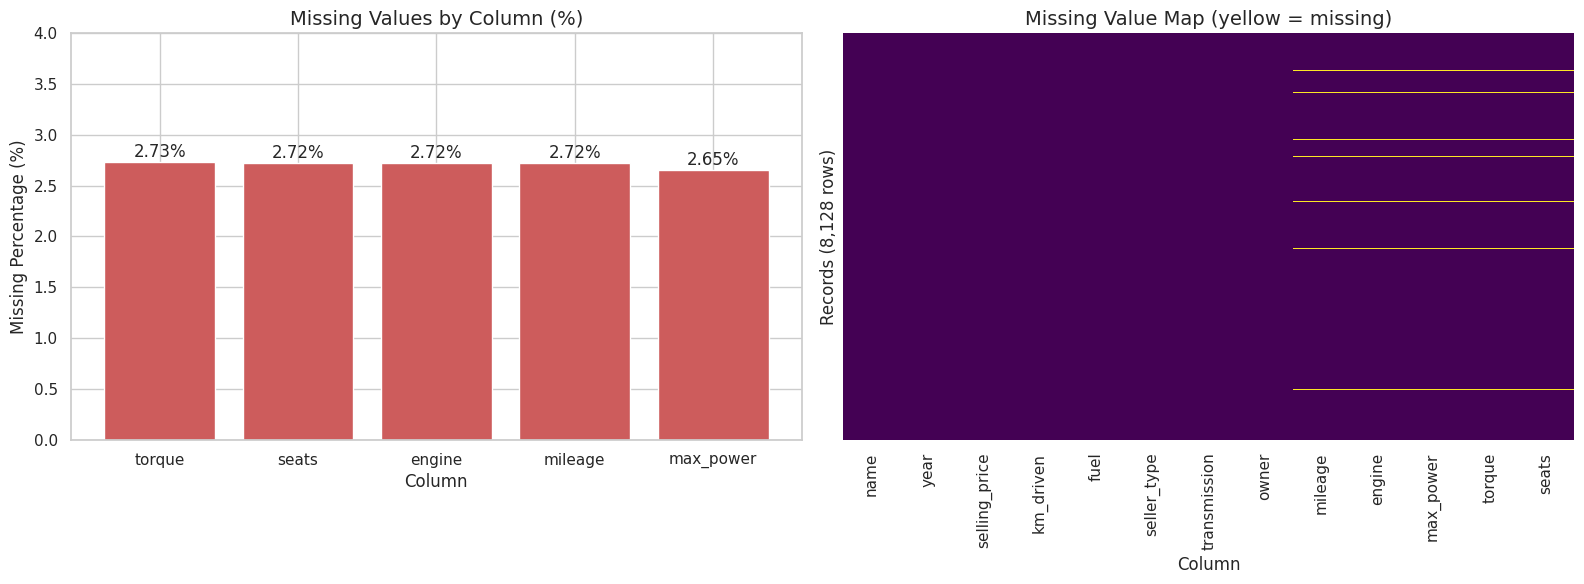

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: bar chart of missing percentage per column
cols_with_na = missing_df[missing_df["Missing Count"] > 0]
axes[0].bar(cols_with_na.index, cols_with_na["Missing %"], color="indianred")
axes[0].set_title("Missing Values by Column (%)")
axes[0].set_xlabel("Column")
axes[0].set_ylabel("Missing Percentage (%)")
axes[0].set_ylim(0, 4)
for i, v in enumerate(cols_with_na["Missing %"]):
    axes[0].text(i, v + 0.05, f"{v}%", ha="center")

# Right: heatmap, one row per record, yellow = missing
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis", ax=axes[1])
axes[1].set_title("Missing Value Map (yellow = missing)")
axes[1].set_xlabel("Column")
axes[1].set_ylabel("Records (8,128 rows)")

plt.tight_layout()
plt.show()

### 4.3 Missing Pattern Check
**Objective:** Confirm with counts whether the gaps occur together in the same rows.

The results show a clear pattern. Of the 8,128 rows, 7,906 have no missing specification values. A total of 215 rows are missing all five specification columns (`mileage`, `engine`, `max_power`, `torque`, `seats`) at the same time. Six rows are missing four columns (all except `max_power`), and one row is missing only `torque`. This means the gaps are structural: these listings do not have a specification sheet. They are not random errors.

In [14]:
spec_cols = ["mileage", "engine", "max_power", "torque", "seats"]

# How many of the 5 spec columns are missing in each row?
gaps_per_row = df[spec_cols].isnull().sum(axis=1)

print("Number of missing spec columns per row:")
display(gaps_per_row.value_counts().sort_index().to_frame("Rows"))

# Do the affected rows share the same pattern?
affected = df[gaps_per_row > 0]
print("\nMissing patterns among the affected rows:")
display(affected[spec_cols].isnull().value_counts().to_frame("Rows"))

Number of missing spec columns per row:


,Rows
0,7906
1,1
4,6
5,215



Missing patterns among the affected rows:


Rows
mileage engine max_power torque seats      
True    True   True      True   True    215
               False     True   True      6
False   False  False     True   False     1

### 4.4 Missing Value Handling Strategy
**Objective:** Decide how to treat the missing values and record the reason.

**Findings**
- 222 rows (2.73%) have at least one missing value. All of them are in the specification columns.
- 215 of these rows are missing all five specification columns at once. The gaps are structural (listings without a specification sheet) and not random.
- Six rows are missing four columns, and one row is missing only `torque`. These are minor exceptions.

**Decision**
- **No imputation.** Filling gaps with the mean or median would create technical specifications for cars where none were recorded.
- The affected rows make up only a small share of the data (2.73%). The 221 rows missing `mileage`, `engine` or `seats` are excluded from analyses that use specification columns. They are kept for analyses that use only price, year, kilometres driven, fuel type, seller type, transmission and owner.
- `torque` has inconsistent units and formats, so it is excluded from the main analysis.

In [15]:
# Rows with a complete specification block
df_specs = df.dropna(subset=["mileage", "engine", "max_power", "seats"]).copy()

print(f"Full dataset (df)           : {len(df):,} rows")
print(f"Rows with complete specs    : {len(df_specs):,} rows")
print(f"Rows excluded from spec work: {len(df) - len(df_specs):,} rows")

Full dataset (df)           : 8,128 rows
Rows with complete specs    : 7,907 rows
Rows excluded from spec work: 221 rows


### 4.5 Duplicate Records
**Objective:** Check whether the dataset contains exact duplicate rows and measure how many.

The dataset contains 1,202 exact duplicate rows (14.79% of all rows), not counting the first occurrence of each record. In total, 1,827 rows belong to a duplicate group. Some listings are repeated several times. For example, the Audi Q5 35TDI Premium Plus (2018) appears six times with identical values in all 13 columns. If these rows are kept, popular listings are counted more than once and every average and chart is affected. Removing the duplicates would leave 6,926 unique records.

In [16]:
dup_count = df.duplicated().sum()
dup_pct = dup_count / len(df) * 100

print(f"Exact duplicate rows (excluding first occurrence): {dup_count:,}")
print(f"Share of dataset                                 : {dup_pct:.2f}%")
print(f"Rows remaining if duplicates are removed         : {len(df) - dup_count:,}")

# Inspect a few duplicated groups side by side
dups = df[df.duplicated(keep=False)].sort_values(list(df.columns))
print(f"\nRows involved in any duplicate group: {len(dups):,}")
display(dups.head(10))

Exact duplicate rows (excluding first occurrence): 1,202
Share of dataset                                 : 14.79%
Rows remaining if duplicates are removed         : 6,926

Rows involved in any duplicate group: 1,827


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
1977,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.00
7324,Audi Q3 2.0 TDI Quattro Premium Plus,2017,2825000,22000,Diesel,Dealer,Automatic,First Owner,15.73 kmpl,1968 CC,174.33 bhp,380Nm@ 1750-2500rpm,5.00
2129,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.00
7775,Audi Q5 3.0 TDI Quattro,2014,1850000,76131,Diesel,Individual,Automatic,First Owner,13.22 kmpl,2967 CC,241.4 bhp,580Nm@ 1400-3250rpm,5.00
131,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.00
1561,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.00
1857,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.00
3236,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.00
5245,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.00
7699,Audi Q5 35TDI Premium Plus,2018,3975000,31800,Diesel,Dealer,Automatic,First Owner,17.01 kmpl,1968 CC,188 bhp,400nm@ 1750-3000rpm,5.00


### 4.6 Duplicate Handling
**Objective:** Decide how to treat the duplicate rows and record the reason.

**Decision:** Exact duplicates are removed, and the first occurrence of each record is kept.

**Reason**
- 1,202 rows (14.79%) are exact copies across all 13 columns, including free-text fields such as `torque`. Matches by coincidence are very unlikely.
- Some listings are repeated up to six times (for example, the Audi Q5 35TDI Premium Plus, 2018). Keeping them would give these cars extra weight in every statistic.
- The dataset has no unique listing ID, so it cannot be proven that these rows are accidental repeats. This is an assumption and is listed as a limitation in Section 8.
- The raw data (`df_raw`) is preserved. All further work uses the de-duplicated dataset (`df_clean`), which has 6,926 rows.

In [17]:
rows_before = len(df)

df_clean = df.drop_duplicates(keep="first").reset_index(drop=True)

rows_after = len(df_clean)
print(f"Rows before : {rows_before:,}")
print(f"Rows after  : {rows_after:,}")
print(f"Removed     : {rows_before - rows_after:,}")
print(f"Duplicates remaining: {df_clean.duplicated().sum()}")

# Re-check missing values after de-duplication
print("\nMissing values after removing duplicates:")
display(df_clean.isnull().sum()[df_clean.isnull().sum() > 0].to_frame("Missing Count"))
print(f"Rows with any gap: {df_clean.isnull().any(axis=1).sum()} "
      f"({df_clean.isnull().any(axis=1).mean()*100:.2f}%)")

Rows before : 8,128
Rows after  : 6,926
Removed     : 1,202
Duplicates remaining: 0

Missing values after removing duplicates:


,Missing Count
mileage,208
engine,208
max_power,205
torque,209
seats,208


Rows with any gap: 209 (3.02%)


### 4.7 Data Quality Summary
**Objective:** Summarise the data quality findings and the actions taken.

- **Missing values:** 222 rows (2.73%) had missing values, all in the five specification columns. Of these, 215 rows were missing all five at once, which points to listings without a specification sheet and not to random loss. No imputation was applied.
- **Duplicates:** 1,202 exact duplicate rows (14.79%) were removed. The dataset was reduced from 8,128 to 6,926 records. Some listings appeared up to six times.
- **Limitation:** The dataset has no listing ID, so duplicates are identified by identical values across all columns.
- **Next step:** Convert `mileage`, `engine` and `max_power` from text to numbers, and create the `age` and `brand` features (Section 5).

## 5. Data Cleaning and Feature Engineering

This section converts text columns that hold numeric values into proper numeric types. It also creates two new features, vehicle age and brand, which are more useful for analysis than the raw columns.

### 5.1 Converting Text Columns to Numeric
**Objective:** Convert `mileage`, `engine` and `max_power` to numbers without losing or corrupting data.

**Approach:** The leading number is extracted from each text value using a regular expression and converted with `pd.to_numeric`. Values that cannot be read become missing values (`NaN`) instead of causing an error. The missing counts before and after conversion are compared to check that nothing was lost.

**Result:** `mileage` and `engine` converted with no new missing values. `max_power` produced one new missing value, which is examined in Section 5.2. The `mileage` column contains two units (`kmpl` for 6,631 rows and `km/kg` for 87 rows), which is handled in Section 5.4.

In [18]:
# Step 1: look at the unit suffixes actually present, before we strip them
for col in ["mileage", "engine", "max_power"]:
    units = df_clean[col].dropna().str.extract(r"([A-Za-z/]+)\s*$")[0].value_counts()
    print(f"{col} units:\n{units.to_string()}\n")

# Step 2: record missing counts before conversion
before_na = df_clean[["mileage", "engine", "max_power"]].isnull().sum()

# Step 3: extract the leading number and convert
df_clean["mileage_kmpl"] = pd.to_numeric(
    df_clean["mileage"].str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
df_clean["engine_cc"] = pd.to_numeric(
    df_clean["engine"].str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
df_clean["max_power_bhp"] = pd.to_numeric(
    df_clean["max_power"].str.extract(r"(\d+\.?\d*)")[0], errors="coerce")

# Step 4: verify that no new missing values were created
after_na = df_clean[["mileage_kmpl", "engine_cc", "max_power_bhp"]].isnull().sum()
check = pd.DataFrame({
    "Missing before": before_na.values,
    "Missing after": after_na.values
}, index=["mileage", "engine", "max_power"])
check["New NaNs"] = check["Missing after"] - check["Missing before"]
display(check)

display(df_clean[["mileage", "mileage_kmpl", "engine", "engine_cc",
                  "max_power", "max_power_bhp"]].head())

mileage units:
0
kmpl     6631
km/kg      87

engine units:
0
CC    6718

max_power units:
0
bhp    6718



,Missing before,Missing after,New NaNs
mileage,208,208,0
engine,208,208,0
max_power,205,206,1


,mileage,mileage_kmpl,engine,engine_cc,max_power,max_power_bhp
0,23.4 kmpl,23.40,1248 CC,"1,248.00",74 bhp,74.00
1,21.14 kmpl,21.14,1498 CC,"1,498.00",103.52 bhp,103.52
2,17.7 kmpl,17.70,1497 CC,"1,497.00",78 bhp,78.00
3,23.0 kmpl,23.00,1396 CC,"1,396.00",90 bhp,90.00
4,16.1 kmpl,16.10,1298 CC,"1,298.00",88.2 bhp,88.20


### 5.2 Investigating a Parsing Failure
**Objective:** Identify which `max_power` values could not be converted and find the cause.

One value could not be converted. The Maruti Omni CNG (row 4273) has the text "bhp" with no number in front of it, so there is nothing to extract. This row became a missing value.

Three other rows (Maruti Alto K10 LXI, Maruti Swift Dzire VDI Optional and Tata Indica Vista Quadrajet LS) contain the value `0` without a unit. These converted without an error, but a power output of 0 bhp is not possible for a running car. They are treated as invalid values in Section 5.3.

In [19]:
# Rows where max_power had text but the numeric conversion failed
failed = df_clean[df_clean["max_power"].notna() & df_clean["max_power_bhp"].isna()]
print(f"Rows that failed to convert: {len(failed)}")
display(failed[["name", "year", "max_power", "max_power_bhp"]])

# Rows where max_power does not follow the usual 'number bhp' pattern
# Adding na=False ensures str.match returns pure boolean Series instead of floats (NaNs)
odd = df_clean[df_clean["max_power"].notna() &
               ~df_clean["max_power"].str.match(r"^\d+\.?\d*\s*bhp$", na=False)]
print(f"\nRows not matching the 'number bhp' pattern: {len(odd)}")
display(odd[["name", "max_power", "max_power_bhp"]])

Rows that failed to convert: 1


,name,year,max_power,max_power_bhp
4273,Maruti Omni CNG,2000,bhp,NaN



Rows not matching the 'number bhp' pattern: 4


,name,max_power,max_power_bhp
547,Maruti Alto K10 LXI,0,0.00
1309,Maruti Swift Dzire VDI Optional,0,0.00
2352,Tata Indica Vista Quadrajet LS,0,0.00
4273,Maruti Omni CNG,bhp,NaN


### 5.3 Handling Invalid Specification Values
**Objective:** Identify impossible values in the converted columns and decide how to treat them.

**Findings**
- One `max_power` entry (Maruti Omni CNG) contains only the unit "bhp" with no number, so it cannot be read. It became a missing value (`NaN`) during the conversion in Section 5.1.
- Three `max_power` entries contain `0` with no unit. A power output of 0 bhp is not possible, so these are placeholder values and not real measurements.
- A zero check on all three converted columns found 15 zero values in `mileage_kmpl` and none in `engine_cc`. A car cannot run at 0 kmpl, so these are also invalid.

**Decision**
- The 18 zero values (3 in `max_power_bhp` and 15 in `mileage_kmpl`) are set to missing (`NaN`). The unreadable "bhp" entry was already missing after conversion, so it needs no further change.
- No imputation is applied, which is consistent with the strategy in Section 4.4.

**Result**
- Missing values after the fix: `mileage_kmpl` 223, `engine_cc` 208 and `max_power_bhp` 209.

In [20]:
spec_num = ["mileage_kmpl", "engine_cc", "max_power_bhp"]

# 1. Count impossible zero values in every converted column
print("Zero values per column (before fix):")
display((df_clean[spec_num] == 0).sum().to_frame("Zeros"))

# 2. Treat zeros as missing
df_clean[spec_num] = df_clean[spec_num].replace(0, np.nan)

# 3. Verify
print("Zero values per column (after fix):")
display((df_clean[spec_num] == 0).sum().to_frame("Zeros"))

print("Missing values in converted columns (after fix):")
display(df_clean[spec_num].isnull().sum().to_frame("Missing Count"))

Zero values per column (before fix):


,Zeros
mileage_kmpl,15
engine_cc,0
max_power_bhp,3


Zero values per column (after fix):


,Zeros
mileage_kmpl,0
engine_cc,0
max_power_bhp,0


Missing values in converted columns (after fix):


,Missing Count
mileage_kmpl,223
engine_cc,208
max_power_bhp,209


### 5.4 Mileage Units and Feature Engineering
**Objective:** Make the mileage values comparable and create the `age` and `brand` features.

**Mileage units**
- The `mileage` column mixes two units: `kmpl` (kilometres per litre) and `km/kg` (kilometres per kilogram of CNG or LPG). These cannot be compared directly.
- `mileage_kmpl` is kept only for rows reported in `kmpl`. The 87 `km/kg` rows are set to missing (`NaN`), and the original unit is stored in a new column, `mileage_unit`.
- After this step, `mileage_kmpl` has 310 missing values (223 from Section 5.3 plus the 87 `km/kg` rows).

**New features**
- `age` = 2020 − `year`. The year 2020 is used as the reference year. This is an assumption, because the collection date of the data is not stated in the dataset. Ages range from 0 to 37 years, with a mean of 6.58.
- `brand` = first word of `name`. This produced 32 brands, led by Maruti (2,165 listings), Hyundai (1,267) and Mahindra (723). Two brands were cut short by the first-word rule and are corrected in Section 5.5.

In [21]:
# A. Mileage unit handling
df_clean["mileage_unit"] = df_clean["mileage"].str.extract(r"(kmpl|km/kg)")[0]
print("Mileage units:")
display(df_clean["mileage_unit"].value_counts(dropna=False).to_frame("Rows"))

df_clean.loc[df_clean["mileage_unit"] == "km/kg", "mileage_kmpl"] = np.nan

# B. Feature engineering
REFERENCE_YEAR = 2020
df_clean["age"] = REFERENCE_YEAR - df_clean["year"]
df_clean["brand"] = df_clean["name"].str.split().str[0]

print("Age summary:")
display(df_clean["age"].describe().to_frame("age").T)

print("Brands found:")
display(df_clean["brand"].value_counts().to_frame("Rows"))

Mileage units:


,Rows
mileage_unit,
kmpl,6631
NaN,208
km/kg,87


Age summary:


,count,mean,std,min,25%,50%,75%,max
age,"6,926.00",6.58,4.08,0.00,3.00,6.00,9.00,37.00


Brands found:


,Rows
brand,
Maruti,2165
Hyundai,1267
Mahindra,723
Tata,647
Honda,362
Ford,361
Toyota,357
Chevrolet,216
Renault,206


### 5.5 Brand Corrections and Final Cleaning Check
**Objective:** Correct brand names that were cut short and confirm the data is ready for analysis.

**Findings**
- Taking the first word of `name` cut two brand names short: `Land` (Land Rover, 3 listings) and `Ashok` (Ashok Leyland, 1 listing).
- Both are corrected manually. The rest of the brand list was reviewed and the names look correct. The total remains 32 brands.
- The maximum vehicle age is 37 years (a 1983 model). This is unusual but plausible, so the record is retained.

**Final cleaning check**
- The cleaned dataset (`df_clean`) has 6,926 rows and 19 columns.
- Missing values in the analysis columns: `mileage_kmpl` 310 (4.48%), `engine_cc` 208 (3.00%), `max_power_bhp` 209 (3.02%) and `seats` 208 (3.00%). All other analysis columns are complete.
- The numeric columns have the correct data types and are ready for analysis.

In [22]:
# Fix fragmented brand names
df_clean["brand"] = df_clean["brand"].replace({"Land": "Land Rover",
                                               "Ashok": "Ashok Leyland"})

print("Fixed brands:")
display(df_clean[df_clean["brand"].isin(["Land Rover", "Ashok Leyland"])]
        ["brand"].value_counts().to_frame("Rows"))
print(f"Unique brands: {df_clean['brand'].nunique()}")

# Final check: dtypes and missing values for analysis columns
analysis_cols = ["selling_price", "km_driven", "age", "mileage_kmpl",
                 "engine_cc", "max_power_bhp", "seats",
                 "fuel", "seller_type", "transmission", "owner", "brand"]
check = pd.DataFrame({
    "dtype": df_clean[analysis_cols].dtypes,
    "missing": df_clean[analysis_cols].isnull().sum(),
    "missing_%": (df_clean[analysis_cols].isnull().mean() * 100).round(2)
})
display(check)
print(f"\nFinal shape: {df_clean.shape}")

Fixed brands:


,Rows
brand,
Land Rover,3
Ashok Leyland,1


Unique brands: 32


,dtype,missing,missing_%
selling_price,int64,0,0.00
km_driven,int64,0,0.00
age,int64,0,0.00
mileage_kmpl,float64,310,4.48
engine_cc,float64,208,3.00
max_power_bhp,float64,209,3.02
seats,float64,208,3.00
fuel,object,0,0.00
seller_type,object,0,0.00
transmission,object,0,0.00



Final shape: (6926, 19)


## 6. Univariate and Bivariate Analysis

This section examines each variable on its own (typical values, spread, shape and extreme values) and then compares variables with each other using charts. Each chart is followed by a short interpretation.

### 6.1 Summary Statistics (Numeric Columns)
**Objective:** Describe the typical values and spread of the numeric columns and measure how skewed they are.

- **Selling price:** The mean (INR 517,271) is well above the median (INR 400,000), and the skew is 5.57. A small number of expensive cars pull the average up. The maximum is INR 10,000,000.
- **Kilometres driven:** The median is 70,000 km and the skew is 11.76. The maximum (2,360,457 km) and the minimum (1 km) look implausible and are examined in Section 6.2.
- **Age:** The mean is 6.58 years and the median is 6 years. The oldest car is 37 years old.
- **Mileage:** The mean (19.48 kmpl) and the median (19.40 kmpl) are almost equal, with a skew of 0.03. The distribution is close to symmetric.
- **Engine size and power:** Both are moderately right-skewed (engine 1.22, power 1.71). The median engine is 1,248 CC and the median power is 81.83 bhp.
- **Seats:** The median is 5, with a range from 2 to 14. Because it has only a few distinct values, it behaves like a category.

In [23]:
num_cols = ["selling_price", "km_driven", "age", "mileage_kmpl",
            "engine_cc", "max_power_bhp", "seats"]

stats = df_clean[num_cols].describe().T
stats["median"] = df_clean[num_cols].median()
stats["skew"] = df_clean[num_cols].skew()
stats = stats[["count", "mean", "median", "std", "min", "25%", "75%", "max", "skew"]]

display(stats)

,count,mean,median,std,min,25%,75%,max,skew
selling_price,"6,926.00","517,270.68","400,000.00","519,766.99","29,999.00","250,000.00","633,500.00","10,000,000.00",5.57
km_driven,"6,926.00","73,995.68","70,000.00","58,358.10",1.00,"40,000.00","100,000.00","2,360,457.00",11.76
age,"6,926.00",6.58,6.00,4.08,0.00,3.00,9.00,37.00,1.01
mileage_kmpl,"6,616.00",19.48,19.40,3.91,9.00,16.80,22.48,42.00,0.03
engine_cc,"6,718.00","1,430.89","1,248.00",493.49,624.00,"1,197.00","1,498.00","3,604.00",1.22
max_power_bhp,"6,717.00",87.77,81.83,31.72,32.80,67.10,100.00,400.00,1.71
seats,"6,718.00",5.43,5.00,0.98,2.00,5.00,5.00,14.00,1.92


### 6.2 Outlier Detection
**Objective:** Identify outliers in `selling_price` and `km_driven` and decide whether they are genuine values or likely data errors.

**Method:** The IQR rule flags values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR. Each flagged group is inspected before any decision is made. A statistical outlier is not automatically an error.

**Results**
- **Selling price:** The upper bound is INR 1,208,750, and 328 listings (4.74%) are above it. The lower bound is negative, so no low-price outliers are flagged.
- **Kilometres driven:** The upper bound is 190,000 km, and 167 listings (2.41%) are above it. The lower bound is negative, so no low-value outliers are flagged by this rule.
- **Most expensive listings:** The top five are a Volvo XC90 T8 (INR 10,000,000), BMW X7, two Audi A6 and a Mercedes-Benz S-Class. All are premium models from 2017 to 2020 with realistic prices.
- **Highest and lowest kilometres driven:** A 2007 Hyundai i20 shows 2,360,457 km and a 2012 Mahindra XUV500 shows 1,500,000 km, both implausible for their age. A 2011 Maruti Eeco CNG shows only 1 km.

,lower_bound,upper_bound,outliers,outlier_%
column,,,,
selling_price,"-325,250.00","1,208,750.00",328,4.74
km_driven,"-50,000.00","190,000.00",167,2.41


Top 5 most expensive listings:


,name,year,selling_price,km_driven,fuel,seller_type
170,Volvo XC90 T8 Excellence BSIV,2017,10000000,30000,Petrol,Individual
2689,BMW X7 xDrive 30d DPE,2020,7200000,5000,Diesel,Individual
4288,Audi A6 35 TFSI Matrix,2019,6523000,23600,Petrol,Dealer
4286,Audi A6 35 TFSI Matrix,2019,6223000,7800,Petrol,Dealer
136,Mercedes-Benz S-Class S 350 CDI,2017,6000000,37000,Diesel,Dealer


Top 5 highest km_driven:


,name,year,selling_price,km_driven,fuel
3161,Hyundai i20 Asta 1.2,2007,550000,2360457,Petrol
1646,Mahindra XUV500 W6 2WD,2012,500000,1500000,Diesel
3183,Maruti Wagon R LXI Minor,2010,194000,577414,Petrol
3284,Maruti Wagon R VXI BS IV,2011,229999,500000,Petrol
5744,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,350000,500000,Diesel


Lowest 5 km_driven:


,name,year,selling_price,km_driven,fuel
6737,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,209000,1,CNG
393,Honda City i-VTEC CVT V,2018,1085000,1000,Petrol
2714,Maruti Swift AMT VXI,2020,654000,1000,Petrol
5710,Toyota Innova Crysta 2.4 ZX AT,2020,2300000,1000,Diesel
6409,Maruti Swift LXI,2020,445000,1000,Petrol


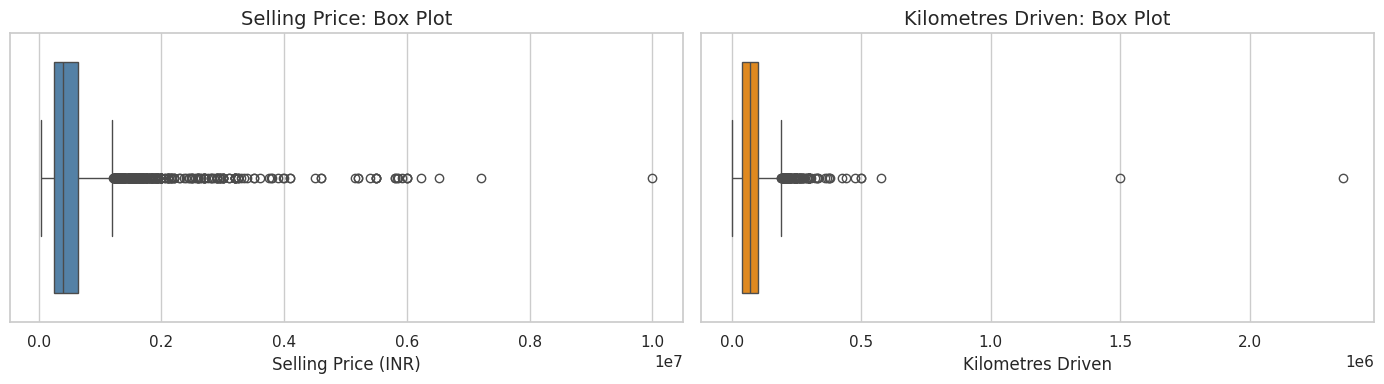

In [24]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows = []
for col in ["selling_price", "km_driven"]:
    lo, hi = iqr_bounds(df_clean[col])
    n_out = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    rows.append({"column": col, "lower_bound": lo, "upper_bound": hi,
                 "outliers": n_out, "outlier_%": round(n_out / len(df_clean) * 100, 2)})
display(pd.DataFrame(rows).set_index("column"))

print("Top 5 most expensive listings:")
display(df_clean.nlargest(5, "selling_price")[["name", "year", "selling_price", "km_driven", "fuel", "seller_type"]])

print("Top 5 highest km_driven:")
display(df_clean.nlargest(5, "km_driven")[["name", "year", "selling_price", "km_driven", "fuel"]])

print("Lowest 5 km_driven:")
display(df_clean.nsmallest(5, "km_driven")[["name", "year", "selling_price", "km_driven", "fuel"]])

# Box plots
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=df_clean["selling_price"], ax=axes[0], color="steelblue")
axes[0].set_title("Selling Price: Box Plot")
axes[0].set_xlabel("Selling Price (INR)")
sns.boxplot(x=df_clean["km_driven"], ax=axes[1], color="darkorange")
axes[1].set_title("Kilometres Driven: Box Plot")
axes[1].set_xlabel("Kilometres Driven")
plt.tight_layout()
plt.show()

### 6.3 Outlier Decision
**Objective:** Decide how to treat the outliers found in Section 6.2 and record the reason.

**Selling price**
- 328 listings (4.74%) are above the IQR upper bound of INR 1,208,750.
- The most expensive listings are recent Volvo, BMW, Audi and Mercedes-Benz models, so these are genuine high-value cars. They are **retained**.
- Because of the strong right skew (5.57), a log scale is used in the charts that follow.

**Kilometres driven**
- 167 listings (2.41%) are above 190,000 km. Most of these are high-mileage but possible, so they are **retained**.
- Three values are judged implausible:
  - Hyundai i20 (2007): 2,360,457 km
  - Mahindra XUV500 (2012): 1,500,000 km
  - Maruti Eeco CNG (2011): 1 km
- These three values are set to missing (`NaN`) in a new column, `km_driven_clean`. The original `km_driven` column is kept unchanged.
- This is a judgement call and not proof of error.

**Result**
- `km_driven_clean` has 6,923 values. The mean falls from 73,996 km to 73,470 km, the median stays at 70,000 km, and the maximum falls from 2,360,457 km to 577,414 km.

In [25]:
df_clean["km_driven_clean"] = df_clean["km_driven"].astype(float)

bad_km = (df_clean["km_driven"] > 1_000_000) | (df_clean["km_driven"] <= 1)
print(f"Rows flagged as implausible: {bad_km.sum()}")
display(df_clean.loc[bad_km, ["name", "year", "km_driven"]])

df_clean.loc[bad_km, "km_driven_clean"] = np.nan

print("km_driven vs km_driven_clean:")
display(df_clean[["km_driven", "km_driven_clean"]].describe().T[["count", "mean", "50%", "max"]])

Rows flagged as implausible: 3


,name,year,km_driven
1646,Mahindra XUV500 W6 2WD,2012,1500000
3161,Hyundai i20 Asta 1.2,2007,2360457
6737,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,1


km_driven vs km_driven_clean:


,count,mean,50%,max
km_driven,"6,926.00","73,995.68","70,000.00","2,360,457.00"
km_driven_clean,"6,923.00","73,470.11","70,000.00","577,414.00"


### 6.4 Chart 1: Distribution of Selling Price
**Objective:** Examine the shape of the selling price distribution and check whether a log scale gives a more balanced view.

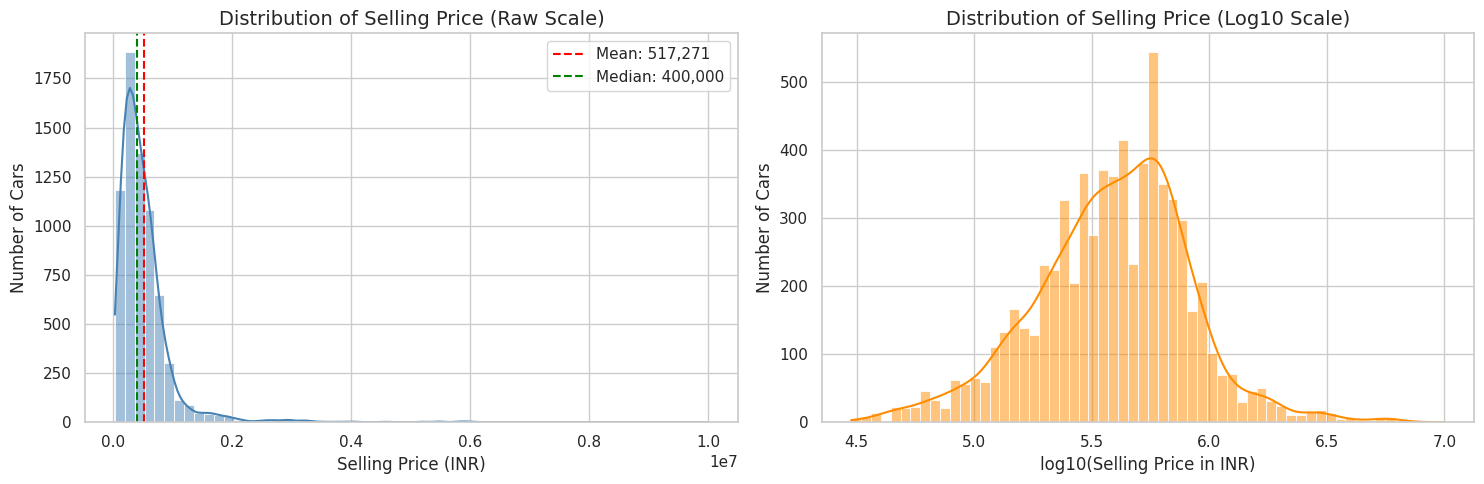

Skew (raw)  : 5.57
Skew (log10): -0.16


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: raw scale
sns.histplot(df_clean["selling_price"], bins=60, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df_clean["selling_price"].mean(), color="red", linestyle="--",
                label=f"Mean: {df_clean['selling_price'].mean():,.0f}")
axes[0].axvline(df_clean["selling_price"].median(), color="green", linestyle="--",
                label=f"Median: {df_clean['selling_price'].median():,.0f}")
axes[0].set_title("Distribution of Selling Price (Raw Scale)")
axes[0].set_xlabel("Selling Price (INR)")
axes[0].set_ylabel("Number of Cars")
axes[0].legend()

# Right: log10 scale
sns.histplot(np.log10(df_clean["selling_price"]), bins=60, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Distribution of Selling Price (Log10 Scale)")
axes[1].set_xlabel("log10(Selling Price in INR)")
axes[1].set_ylabel("Number of Cars")

plt.tight_layout()
plt.show()

print(f"Skew (raw)  : {df_clean['selling_price'].skew():.2f}")
print(f"Skew (log10): {np.log10(df_clean['selling_price']).skew():.2f}")

**Interpretation:** The raw distribution is strongly right-skewed (skew 5.57). Most cars sell at the lower end of the range, while a small number of premium cars stretch the tail towards INR 10,000,000. This pulls the mean (INR 517,271) above the median (INR 400,000). After a log10 transformation, the skew falls to -0.16, and the distribution is close to symmetric. Log price is therefore a better scale for correlation analysis and modelling.

### 6.5 Chart 2: Vehicle Age vs Selling Price
**Objective:** Examine how a car's selling price changes with age and check whether the pattern holds across all ages.

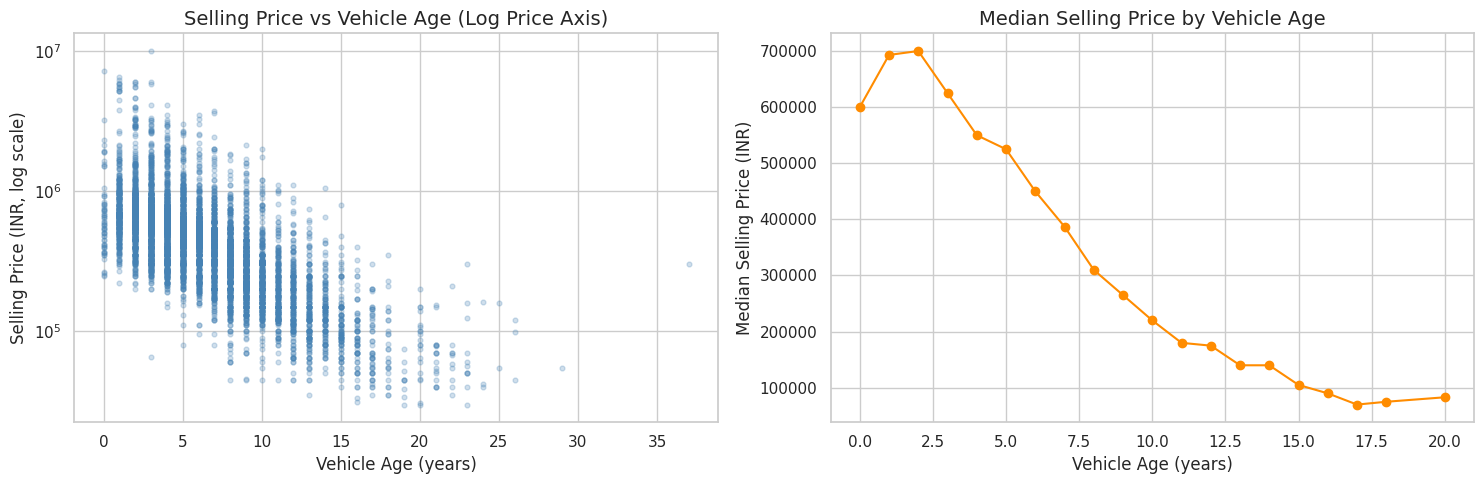

Correlation (age vs log10 price): -0.719


age,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,20
median,"600,000.00","693,000.00","700,000.00","625,000.00","550,000.00","525,000.00","450,000.00","387,000.00","310,000.00","265,000.00","220,000.00","180,000.00","175,000.00","140,000.00","140,000.00","105,000.00","90,000.00","70,000.00","75,000.00","83,000.00"
count,63.00,347.00,608.00,808.00,693.00,681.00,581.00,562.00,604.00,554.00,380.00,240.00,205.00,176.00,123.00,91.00,60.00,47.00,26.00,20.00


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: scatter on log price, with jitter-free alpha for overplotting
axes[0].scatter(df_clean["age"], df_clean["selling_price"], alpha=0.25, s=12, color="steelblue")
axes[0].set_yscale("log")
axes[0].set_title("Selling Price vs Vehicle Age (Log Price Axis)")
axes[0].set_xlabel("Vehicle Age (years)")
axes[0].set_ylabel("Selling Price (INR, log scale)")

# Right: median price by age (ages with at least 20 cars)
g = df_clean.groupby("age")["selling_price"].agg(["median", "count"])
g = g[g["count"] >= 20]
axes[1].plot(g.index, g["median"], marker="o", color="darkorange")
axes[1].set_title("Median Selling Price by Vehicle Age")
axes[1].set_xlabel("Vehicle Age (years)")
axes[1].set_ylabel("Median Selling Price (INR)")

plt.tight_layout()
plt.show()

print("Correlation (age vs log10 price):",
      round(df_clean["age"].corr(np.log10(df_clean["selling_price"])), 3))
display(g.round(0).T)

**Interpretation:** Selling price falls steadily with age (correlation with log price = -0.72). The median drops from INR 700,000 at age 2 to INR 220,000 at age 10, a fall of about 69%. The wide spread at each age shows that other factors, such as brand and engine power, also affect price.

**Note:** Age 0 (63 cars) and ages above 17 (fewer than 30 cars each) have small samples, so their medians are less reliable.

### 6.6 Chart 3: Price by Fuel Type and Transmission
**Objective:** Check whether fuel type and transmission type are linked to different price levels.

**Note:** Differences between groups may partly reflect differences in car age or segment, and not a pure effect of fuel type or transmission. For this reason, the median age of each group is shown next to its median price.

Cars per fuel type:


,Cars
fuel,
Diesel,3755
Petrol,3077
CNG,56
LPG,38


Cars per transmission:


,Cars
transmission,
Manual,6342
Automatic,584


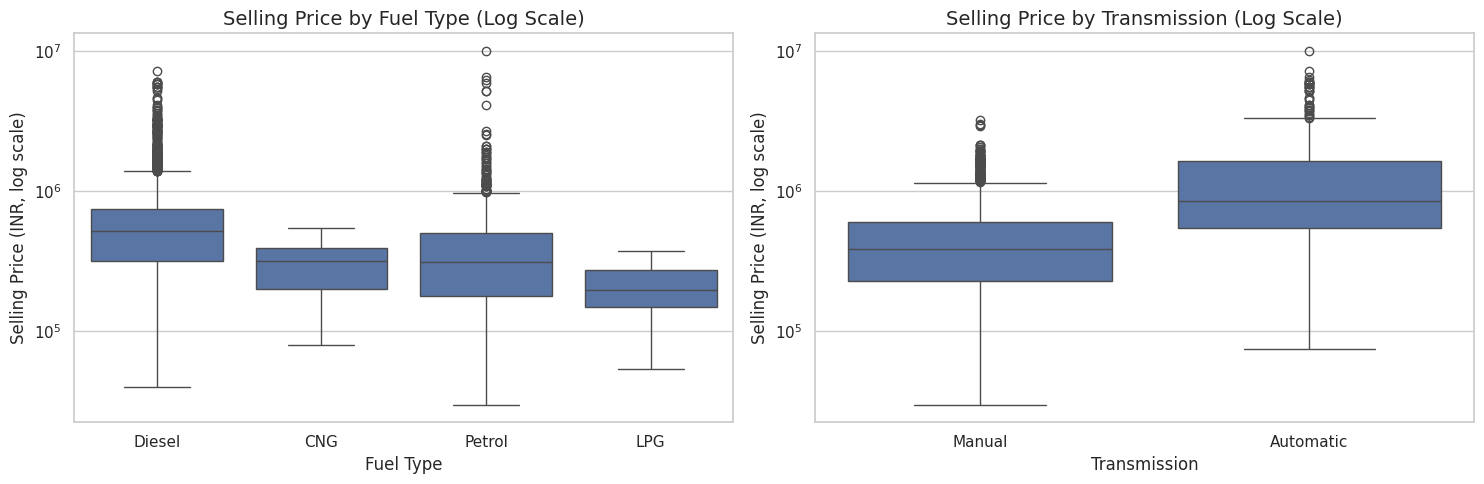

Median price and median age by group:


,selling_price,age
fuel,,
CNG,"320,000.00",4.00
Diesel,"520,000.00",6.00
LPG,"195,500.00",10.00
Petrol,"310,000.00",6.00


,selling_price,age
transmission,,
Automatic,"850,000.00",4.00
Manual,"385,000.00",6.00


In [28]:
# Group sizes first, so we know which groups are too small to trust
print("Cars per fuel type:")
display(df_clean["fuel"].value_counts().to_frame("Cars"))
print("Cars per transmission:")
display(df_clean["transmission"].value_counts().to_frame("Cars"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: fuel type
fuel_order = df_clean.groupby("fuel")["selling_price"].median().sort_values(ascending=False).index
sns.boxplot(data=df_clean, x="fuel", y="selling_price", order=fuel_order, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Selling Price by Fuel Type (Log Scale)")
axes[0].set_xlabel("Fuel Type")
axes[0].set_ylabel("Selling Price (INR, log scale)")

# Right: transmission
sns.boxplot(data=df_clean, x="transmission", y="selling_price", ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Selling Price by Transmission (Log Scale)")
axes[1].set_xlabel("Transmission")
axes[1].set_ylabel("Selling Price (INR, log scale)")

plt.tight_layout()
plt.show()

print("Median price and median age by group:")
display(df_clean.groupby("fuel")[["selling_price", "age"]].median())
display(df_clean.groupby("transmission")[["selling_price", "age"]].median())

**Interpretation:** Diesel cars have a higher median price (INR 520,000) than petrol cars (INR 310,000) even though both have the same median age of 6 years, so age does not explain the gap. Automatic cars are priced much higher than manual cars (INR 850,000 vs INR 385,000), but they are also 2 years younger (median age 4 vs 6), so part of this gap is an age effect.

**Note:** Automatic cars are only 8.4% of listings (584 of 6,926). CNG (56 cars) and LPG (38 cars) are too small for reliable conclusions.

### 6.7 Chart 4: Correlation Heatmap
**Objective:** Identify which numeric features are most strongly related to selling price and to each other.

**Method:** Pearson correlation is calculated for `log_price` (log10 of selling price), `age`, `km_driven_clean`, `engine_cc`, `max_power_bhp`, `mileage_kmpl` and `seats`. Log price is used because the raw price is strongly skewed. Rows with missing values are excluded pair by pair.

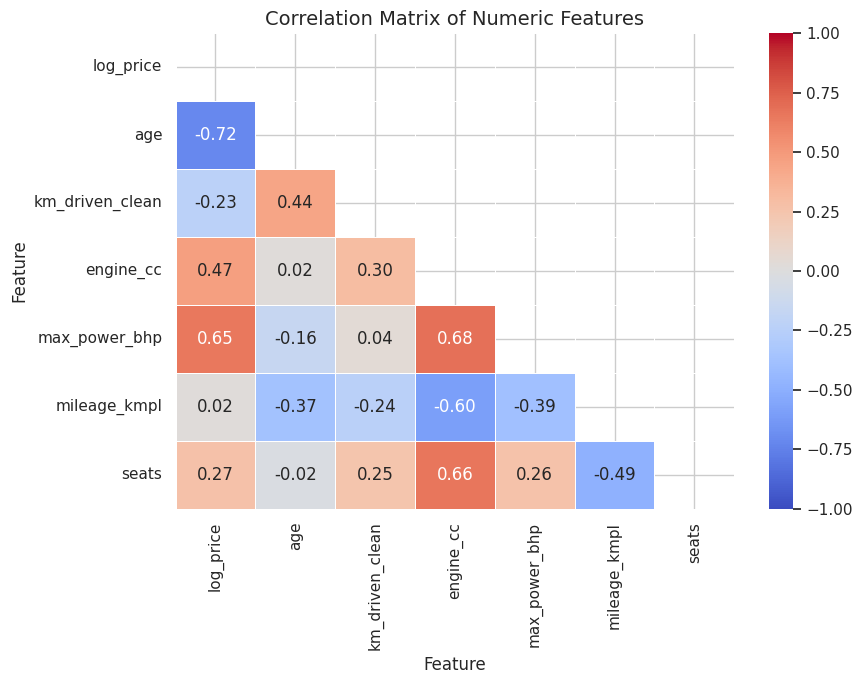

Correlation with log_price (sorted):


,corr with log_price
age,-0.72
km_driven_clean,-0.23
mileage_kmpl,0.02
seats,0.27
engine_cc,0.47
max_power_bhp,0.65


In [29]:
df_clean["log_price"] = np.log10(df_clean["selling_price"])

corr_cols = ["log_price", "age", "km_driven_clean", "engine_cc",
             "max_power_bhp", "mileage_kmpl", "seats"]
corr = df_clean[corr_cols].corr()

plt.figure(figsize=(9, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numeric Features")
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Correlation with log_price (sorted):")
display(corr["log_price"].drop("log_price").sort_values().to_frame("corr with log_price"))

**Interpretation:** Age has the strongest relationship with log price (r = -0.72), followed by maximum power (r = +0.65) and engine size (r = +0.47), while kilometres driven (r = -0.23) and mileage (r = +0.02) show weak or no relationship. Engine size and maximum power are also correlated with each other (r = 0.68), so they partly carry the same information.

**Note:** These values measure linear association only and do not prove cause and effect.

### 6.8 Chart 5: Brands by Count and by Median Price
**Objective:** Identify which brands have the most listings and which have the highest prices.

**Method:** Brands with fewer than 30 listings are excluded from the price ranking, because medians from very small groups are unreliable.

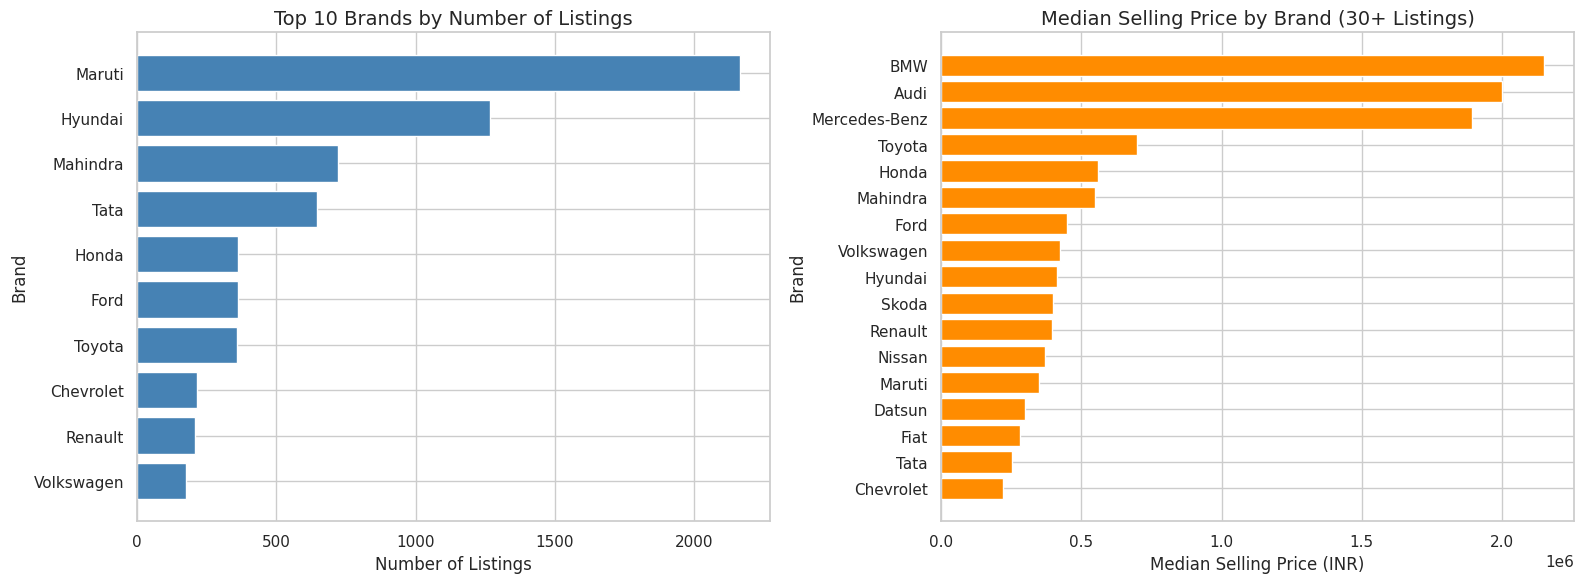

Top 3 brands share of all listings: 60.0%


,count,median_price
brand,,
BMW,47,"2,150,000.00"
Audi,33,"2,000,000.00"
Mercedes-Benz,46,"1,892,000.00"
Toyota,357,"700,000.00"
Honda,362,"560,000.00"


,count,median_price
brand,,
Maruti,2165,"350,000.00"
Datsun,57,"300,000.00"
Fiat,44,"282,500.00"
Tata,647,"252,999.00"
Chevrolet,216,"220,000.00"


In [30]:
brand_stats = (df_clean.groupby("brand")["selling_price"]
               .agg(count="count", median_price="median")
               .sort_values("count", ascending=False))

top_brands = brand_stats.head(10)
reliable = brand_stats[brand_stats["count"] >= 30].sort_values("median_price", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: top 10 brands by number of listings
axes[0].barh(top_brands.index[::-1], top_brands["count"][::-1], color="steelblue")
axes[0].set_title("Top 10 Brands by Number of Listings")
axes[0].set_xlabel("Number of Listings")
axes[0].set_ylabel("Brand")

# Right: median price, brands with 30+ listings
axes[1].barh(reliable.index[::-1], reliable["median_price"][::-1], color="darkorange")
axes[1].set_title("Median Selling Price by Brand (30+ Listings)")
axes[1].set_xlabel("Median Selling Price (INR)")
axes[1].set_ylabel("Brand")

plt.tight_layout()
plt.show()

print(f"Top 3 brands share of all listings: "
      f"{top_brands['count'].head(3).sum() / len(df_clean) * 100:.1f}%")
display(reliable.head(5))
display(reliable.tail(5))

**Interpretation:** The market is concentrated: Maruti, Hyundai and Mahindra together account for 60.0% of all listings. BMW (median INR 2,150,000), Audi (INR 2,000,000) and Mercedes-Benz (INR 1,892,000) are priced about 10 times higher than the cheapest brand, Chevrolet (INR 220,000), and having the most listings does not mean a high price (Maruti's median is only INR 350,000).

**Note:** Brand medians are not adjusted for car age or model segment.

### 6.9 Categorical Value Counts

1.   List item
2.   List item


**Objective:** Describe the distribution of `owner`, `seller_type` and `seats`, and identify groups that are too small to analyse.

--- owner ---


,Cars,Share %
owner,,
First Owner,4242,61.20
Second Owner,1974,28.50
Third Owner,536,7.70
Fourth & Above Owner,169,2.40
Test Drive Car,5,0.10


--- seller_type ---


,Cars,Share %
seller_type,,
Individual,6218,89.80
Dealer,681,9.80
Trustmark Dealer,27,0.40


--- seats ---


,Cars,Share %
seats,,
5.00,5254,75.90
7.00,966,13.90
8.00,222,3.20
NaN,208,3.00
4.00,124,1.80
9.00,74,1.10
6.00,57,0.80
10.00,18,0.30
2.00,2,0.00


Median price by owner type:


,selling_price,age
owner,,
First Owner,"500,000.00",4.00
Fourth & Above Owner,"170,000.00",12.00
Second Owner,"305,000.00",8.00
Test Drive Car,"5,923,000.00",1.00
Third Owner,"222,500.00",10.00


Median price by seller type:


,selling_price,age
seller_type,,
Dealer,"620,000.00",4.00
Individual,"390,000.00",6.00
Trustmark Dealer,"650,000.00",3.00


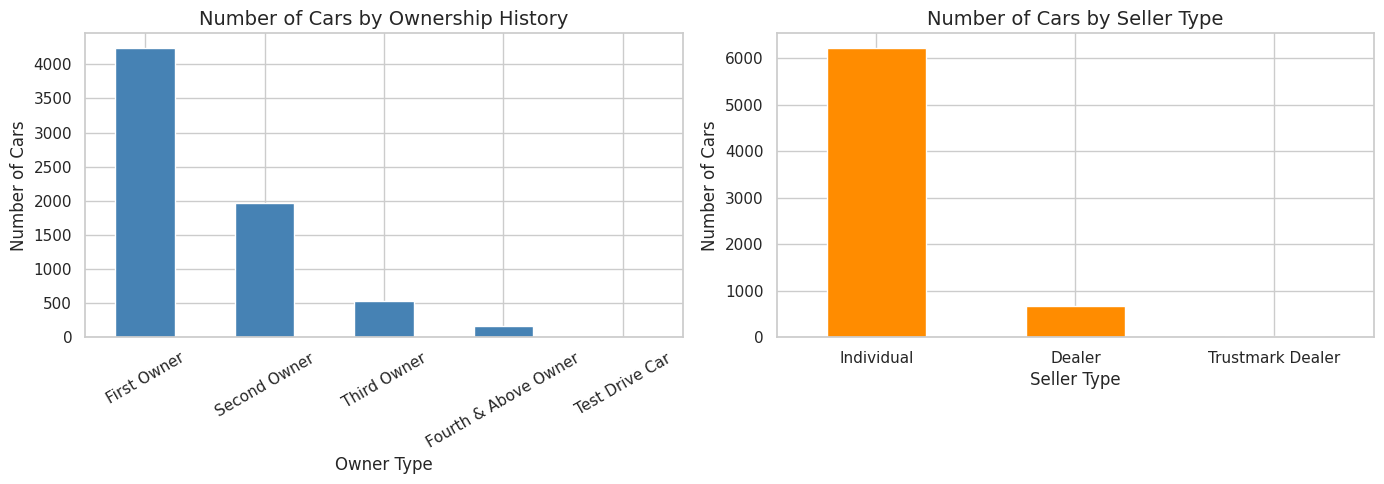

In [31]:
for col in ["owner", "seller_type", "seats"]:
    vc = df_clean[col].value_counts(dropna=False)
    out = pd.DataFrame({"Cars": vc, "Share %": (vc / len(df_clean) * 100).round(1)})
    print(f"--- {col} ---")
    display(out)

print("Median price by owner type:")
display(df_clean.groupby("owner")[["selling_price", "age"]].median())

print("Median price by seller type:")
display(df_clean.groupby("seller_type")[["selling_price", "age"]].median())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_clean["owner"].value_counts().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Number of Cars by Ownership History")
axes[0].set_xlabel("Owner Type")
axes[0].set_ylabel("Number of Cars")
axes[0].tick_params(axis="x", rotation=30)

df_clean["seller_type"].value_counts().plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Number of Cars by Seller Type")
axes[1].set_xlabel("Seller Type")
axes[1].set_ylabel("Number of Cars")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Interpretation:** The number of cars drops with each additional owner, while median price falls from INR 500,000 (first owner) to INR 170,000 (fourth and above). Median age rises at the same time (4 to 12 years), so part of the price drop is an age effect. Individual sellers account for most listings, but dealer cars have a higher median price (INR 620,000 vs INR 390,000) and are 2 years younger (4 vs 6 years). Most cars have 5 seats.

**Note:** The "Test Drive Car" and "Trustmark Dealer" groups are too small for reliable conclusions. 208 rows (3.00%) have no seat value.

## 7. Key Findings

1. **Price is strongly right-skewed.** The mean (INR 517,271) is well above the median (INR 400,000), because a small number of expensive cars pull the average up (skew 5.57). After a log10 transformation the skew falls to -0.16, so log price is a better scale for correlation and modelling.

2. **Age is the factor most strongly related to price.** The correlation between age and log price is -0.72. The median price falls from INR 700,000 at age 2 to INR 220,000 at age 10, a drop of about 69%.

3. **Engine power is more closely related to price than engine size.** Maximum power has a correlation of +0.65 with log price, compared with +0.47 for engine size. The two overlap (r = 0.68), and mileage shows almost no relationship with price (r = +0.02).

4. **Brand sets the price tier.** BMW, Audi and Mercedes-Benz have median prices of INR 1.9 to 2.15 million, about 10 times the median of Chevrolet (INR 220,000). Maruti has the most listings (2,165) but one of the lowest median prices (INR 350,000).

5. **Price gaps by transmission and seller type are partly an age effect.** Automatic cars (median INR 850,000) and dealer cars (INR 620,000) are priced much higher than manual cars (INR 385,000) and individual sellers' cars (INR 390,000). Both groups are also 2 years younger (median age 4 vs 6), so these gaps should not be read as pure transmission or seller effects.

**Data quality note:** 1,202 exact duplicate rows (14.79%) were removed. Three implausible `km_driven` values, three zero `max_power` values and 15 zero `mileage` values were set to missing.

## 8. Limitations and Conclusion

### 8.1 Limitations
- **Duplicates:** The dataset has no listing ID, so duplicates were identified by identical values in all columns. Some removed rows may have been genuine separate listings.
- **Reference year:** Age is calculated using 2020 as the reference year. This is an assumption, because the collection date is not stated in the dataset.
- **No adjustment for other factors:** Comparisons by fuel type, transmission, seller type, owner and brand are not adjusted for age or car segment. They show association, not cause and effect.
- **Small groups:** CNG (56 cars), LPG (38 cars), Trustmark Dealer and Test Drive Car are too small for reliable conclusions.
- **Judgement calls:** Three `km_driven` values (Section 6.3) and the zero values in `max_power` and `mileage` (Section 5.3) were set to missing based on judgement, not proof of error.
- **Missing specifications:** About 3% of listings have no technical specifications. These rows were not filled in, so specification analyses use fewer rows.
- **Mileage units:** 87 CNG and LPG cars report mileage in `km/kg` and are excluded from `mileage_kmpl`.
- **Correlation only:** The correlations measure linear association. No predictive model was built.

### 8.2 Conclusion
This analysis examined 6,926 unique used car listings after removing duplicates and fixing invalid values. Vehicle age (r = -0.72), maximum power (r = +0.65) and brand are the factors most strongly linked to selling price. Price is strongly right-skewed, so a log scale suits further analysis. Dealer, automatic and diesel cars are priced higher. For dealer and automatic cars, part of the gap is linked to age, while the diesel gap is not explained by age and may reflect car segment. Each cleaning decision is documented above, because several of them (duplicates, invalid values) changed the data. A suitable next step is a regression model on log price using age, brand and maximum power.